# Exclusion follow-up: is the IOI circuit triggered by repetition or by the relation? (Colab, GPT-2 Medium + GPT-2 small)

The relational screen found that GPT-2 Medium solves "relational" exclusion prompts (equality,
inequality, spatial, elimination, set removal) with the IOI circuit, and fails when nothing is repeated
or when the repeated item is the answer. Two weaknesses: the no-repeat condition also changed the
question form, and with two entities any true statement "X relation ___" must end in the other entity,
so the relation could never change the answer. This notebook fixes both.

| Test | Design | If the circuit is relation-blind and repetition-triggered |
|---|---|---|
| **T1 minimal pairs** | Each base prompt gets two twins that change one slot: **flip** (relation word reversed, or negation removed) and **no-repeat** (the repeated mention replaced by a new token of the same kind) | Flip: preference for the non-repeated candidate barely moves. No-repeat: preference collapses and inhibitors stop attending to the candidates |
| **T2 DoubleIO / TripleIO analogues** | Extra sentences mention the *answer* once or twice more, so raw counts no longer single it out (Nainani et al. 2024 design, in new domains) | If the trigger is "repeat of the current subject", accuracy holds; if it is "fewest mentions", Double → chance and Triple → wrong |
| **T3 three-entity chains** | "The lamp is directly left of the chair, and the chair is directly left of the sofa. So directly left of the sofa is the" → chair. Half the items make the least-mentioned entity wrong (*inconsistent*), half right (*consistent*) | High on consistent, low on inconsistent |
| **T4 few-shot relation-only** | Two candidates, nothing repeated, 0 / 1 / 2 solved examples (entities disjoint from the test item) | Stays near chance even with examples |
| **T5 ablation, measured properly** | Logit-difference effects; mean **and** resample ablation; inhibitors and negative movers forced separately; random head sets | Inhibition/dup heads drive the non-repeated preference everywhere, beyond random sets |
| **T6 per-head map** | Mean-ablate every head on IOI, equality, spatial, set removal and Greater-Than | Exclusion tasks' head maps correlate with IOI's far more than Greater-Than's does |

Everything runs on **GPT-2 Medium** (Merullo head lists) and **GPT-2 small** (Wang et al. head lists,
the fully mapped IOI circuit) as a replication.

**Key quantity: preference for the reference candidate.** For every two-candidate prompt, *ref* is
the candidate the exclusion rule picks in the base twin (the non-repeated one).
ref-pref = logit(ref) − logit(other). It is defined for every variant, so twins can be compared
directly even where no answer is correct (invalid flips, no-repeat twins).

**Before running**
- Runtime → T4 GPU → Run all. Not timed on a GPU. My estimate is **about an hour** for both models
  (most of it the per-head map and random head sets on GPT-2 Medium). `QUICK = True` is roughly
  15–20 min; `RUN_HEAD_SCAN = False` or `MODELS = ["gpt2-medium"]` trim further.
- `SMOKE = True` runs tiny random models on CPU to test the code only.
- All thresholds in `TH` are proposals; treat this as pilot data and fix them before a confirmatory run.

TransformerLens 4.0 removed `HookedTransformer`, so the install is pinned to the last 2.x release.

In [1]:
%pip install -q --no-deps transformer_lens==2.18.0
%pip install -q einops jaxtyping fancy_einsum better_abc typeguard beartype datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.9/239.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 1.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformer-lens 2.18.0 requires transformers-stream-generator<0.0.6,>=0.0.5, which is not installed.
transformer-lens 2.18.0 requires beartype<0.15.0,>=0.14.1, but you have beartype 0.22.9 which is incompatible.
transformer-lens 2.18.0 requires huggingface-hub<1.0,>=0.23.2, but you have huggingface-hub 1.33.0 which is incompatible.


## Configuration

In [2]:
MODELS = ["gpt2-medium", "gpt2"]
SMOKE = False
QUICK = False
RUN_HEAD_SCAN = True

SEED = 0
PREPEND_BOS = False
BATCH = 64
N_PER = 200                 # items per condition (minimal-pair twins share items)
N_RAND_SETS = 10            # random layer-matched head sets per group (core conditions only)
N_SCAN = 80                 # prompts per condition for the per-head map
SHOTS = [0, 1, 2]

# Head lists. GPT-2 Medium: Merullo, Eickhoff & Pavlick (ICLR 2024). GPT-2 small: Wang et al. (ICLR 2023).
MODEL_CFG = {
    "gpt2-medium": dict(groups={
        "dup/induction": [(6, 4), (6, 15), (7, 2), (9, 3), (9, 9)],
        "inhibition":    [(12, 3), (13, 4), (13, 13)],
        "gatherer":      [(11, 6), (11, 7), (12, 15)],
        "mover":         [(15, 14), (16, 15), (17, 4), (18, 5), (19, 15)],
        "neg mover":     [(19, 1)]}),
    "gpt2": dict(groups={
        "dup/induction": [(0, 1), (0, 10), (3, 0), (5, 5), (6, 9)],
        "inhibition":    [(7, 3), (7, 9), (8, 6), (8, 10)],
        "mover":         [(9, 6), (9, 9), (10, 0)],
        "neg mover":     [(10, 7), (11, 10)]}),
}
SCAN_CONDS = ["ioi/base", "equality/base", "spatial/base", "set_removal/base", "REF Greater-Than"]

TH = dict(norep_collapse=0.70,    # T1: no-repeat twin loses >= 70% of base ref-pref
          flip_insensitive=0.25,  # T1: invalid flip changes ref-pref by < 25% of base
          triple_hold=0.90,       # T2: accuracy on TripleIO analogue stays >= 0.90
          chain_gap=0.30,         # T3: consistent minus inconsistent accuracy >= 0.30
          fewshot_margin=0.20,    # T4: relation-only stays below chance + 0.20 at 2 shots
          scan_gap=0.20)          # T6: corr(task, IOI) - corr(Greater-Than, IOI) >= 0.20
N_BOOT = 1000
OUT_DIR = "exclusion_followup_results"
SAVE_TO_DRIVE = False

if QUICK:
    N_PER, N_RAND_SETS, N_SCAN, N_BOOT = 100, 5, 48, 300
if SMOKE:
    N_PER, N_RAND_SETS, N_SCAN, N_BOOT, BATCH = 16, 2, 8, 50, 16

## Setup

In [3]:
import os, re, json, math, random, time, gc
from collections import defaultdict
from functools import partial
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from importlib.metadata import version as _ver
TL_VERSION = _ver("transformer_lens")
assert int(TL_VERSION.split(".")[0]) < 4, f"TransformerLens {TL_VERSION} has no HookedTransformer; run the install cell (2.18.0)"
from transformer_lens import HookedTransformer, HookedTransformerConfig

torch.set_grad_enabled(False)
os.makedirs(OUT_DIR, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() and not SMOKE else "cpu"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | transformer_lens {TL_VERSION} | {DEV}")


class ToyTokenizer:
    """Word-level stand-in for SMOKE runs."""
    def __init__(self, vocab_size):
        self.vocab, self.V = {"<|endoftext|>": 0}, vocab_size
        self.eos_token_id = self.bos_token_id = 0

    def __call__(self, text, return_offsets_mapping=True, add_special_tokens=False):
        ids, offs = [], []
        for m in re.finditer(r" ?[A-Za-z]+| ?[0-9]{1,2}| ?[^\sA-Za-z0-9]|\n| ", text):
            t = m.group()
            if t not in self.vocab:
                assert len(self.vocab) < self.V, "toy vocab full"
                self.vocab[t] = len(self.vocab)
            ids.append(self.vocab[t]); offs.append((m.start(), m.end()))
        return {"input_ids": ids, "offset_mapping": offs}


TOY_TOK = ToyTokenizer(3000) if SMOKE else None
model = tok = None


def load(name):
    global model, tok, NL, NH, D, DH, PAD_ID
    if model is not None:
        del model; gc.collect()
        if DEV == "cuda": torch.cuda.empty_cache()
    if SMOKE:
        nl, nh = (24, 16) if name == "gpt2-medium" else (12, 12)
        cfg = HookedTransformerConfig(n_layers=nl, d_model=4 * nh, n_heads=nh, d_head=4, d_mlp=128, n_ctx=512,
                                      d_vocab=3000, act_fn="gelu_new", normalization_type="LNPre", seed=SEED)
        model = HookedTransformer(cfg).to(DEV)
        for n_, p in model.named_parameters():
            if "W_" in n_: p.data *= 4          # sharper attention so the toy model's hooks get exercised
        tok = TOY_TOK
    else:
        model = HookedTransformer.from_pretrained(name, center_unembed=True, center_writing_weights=True,
                                                  fold_ln=True, device=DEV)
        tok = model.tokenizer
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    NL, NH, D, DH = model.cfg.n_layers, model.cfg.n_heads, model.cfg.d_model, model.cfg.d_head
    PAD_ID = tok.eos_token_id
    print(f"loaded {name}{' (SMOKE toy)' if SMOKE else ''}: {NL} layers x {NH} heads")


def encode(text, bos=PREPEND_BOS):
    enc = tok(text, return_offsets_mapping=True, add_special_tokens=False)
    ids, offs = list(enc["input_ids"]), list(enc["offset_mapping"])
    if bos:
        ids, offs = [tok.bos_token_id] + ids, [(0, 0)] + offs
    return ids, offs


def single_token(s):
    ids, _ = encode(s, bos=False)
    return ids[0] if len(ids) == 1 else None


SETS = ["ref", "other", "subj", "least"]


def pad(batch):
    T = max(len(q["ids"]) for q in batch)
    toks = torch.full((len(batch), T), PAD_ID, dtype=torch.long)
    M = torch.zeros(len(batch), len(SETS), T)
    for i, q in enumerate(batch):
        toks[i, :len(q["ids"])] = torch.tensor(q["ids"])
        for s, name in enumerate(SETS):
            if q["sets"][name]:
                M[i, s, q["sets"][name]] = 1.0
    return toks.to(DEV), torch.tensor([q["last"] for q in batch]).to(DEV), M.to(DEV)


def _grab(x, hook, store, name, ar, lasts, M):
    if name.endswith("hook_pattern"):
        store[name] = torch.einsum("bht,bst->bhs", x[ar, :, lasts, :], M)
    else:
        store[name] = x[ar, lasts]
    return x


def run_batch(prompts, idx, builders=(), grab=()):
    batch = [prompts[i] for i in idx]
    toks, lasts, M = pad(batch)
    ar = torch.arange(len(batch), device=DEV)
    idx_t = torch.tensor(idx, device=DEV)
    store, hs = {}, []
    for b in builders:
        hs += b(idx_t, lasts, ar, batch)
    for name in grab:
        hs.append((name, partial(_grab, store=store, name=name, ar=ar, lasts=lasts, M=M)))
    hs.append(("ln_final.hook_normalized", partial(_grab, store=store, name="final", ar=ar, lasts=lasts, M=M)))
    model.run_with_hooks(toks, return_type=None, fwd_hooks=hs)
    return (store.pop("final") @ model.W_U + model.b_U).float(), store


def run(prompts, builders=(), grab=(), bs=None):
    bs = bs or BATCH
    LG, ST = [], defaultdict(list)
    for s in range(0, len(prompts), bs):
        lg, st = run_batch(prompts, list(range(s, min(s + bs, len(prompts)))), builders, grab)
        LG.append(lg.cpu())
        for k, v in st.items():
            ST[k].append(v.float().cpu())
    return torch.cat(LG), {k: torch.cat(v) for k, v in ST.items()}


def mean_z(prompts):
    sums, cnt = torch.zeros(NL, NH, DH, device=DEV), 0.0
    for s in range(0, len(prompts), BATCH):
        toks, lasts, _ = pad(prompts[s:s + BATCH])
        mask = (torch.arange(toks.shape[1], device=DEV)[None] <= lasts[:, None]).float()
        def f(z, hook):
            sums[hook.layer()] += torch.einsum("bthd,bt->hd", z, mask); return z
        model.run_with_hooks(toks, return_type=None, fwd_hooks=[(lambda n: n.endswith("attn.hook_z"), f)])
        cnt += mask.sum().item()
    return sums / cnt


def _by_layer(heads):
    d = defaultdict(list)
    for l, h in heads:
        d[l].append(h)
    return d


def hb_ablate(heads, MZ):
    """Mean ablation at every position."""
    def builder(idx, lasts, ar, batch):
        hs = []
        for l, hl in _by_layer(heads).items():
            def f(z, hook, l=l, hl=hl):
                z = z.clone(); z[:, :, hl, :] = MZ[l, hl]; return z
            hs.append((f"blocks.{l}.attn.hook_z", f))
        return hs
    return builder


def hb_resample(heads, P, partner):
    """Resample ablation: each prompt gets these heads' outputs from a partner prompt of the same
    template and token length (so positions align), at every position."""
    by_l = _by_layer(heads)
    def builder(idx, lasts, ar, batch):
        src = [P[partner[i]] for i in idx.tolist()]
        toks, _, _ = pad(src)
        cache = {}
        def g(z, hook):
            cache[hook.layer()] = z; return z
        model.run_with_hooks(toks, return_type=None, fwd_hooks=[(f"blocks.{l}.attn.hook_z", g) for l in by_l])
        hs = []
        for l, hl in by_l.items():
            def f(z, hook, l=l, hl=hl):
                z = z.clone(); z[:, :, hl, :] = cache[l][:, :, hl, :]; return z
            hs.append((f"blocks.{l}.attn.hook_z", f))
        return hs
    return builder


def hb_force(heads, pos_fn):
    """Force heads' attention from the final position to be uniform over pos_fn(q)."""
    def builder(idx, lasts, ar, batch):
        T = max(len(q["ids"]) for q in batch)
        rows, use = torch.zeros(len(batch), T), torch.zeros(len(batch), dtype=torch.bool)
        for i, q in enumerate(batch):
            ps = pos_fn(q)
            if ps:
                rows[i, ps] = 1.0 / len(set(ps)); use[i] = True
        rows, use = rows.to(DEV), use.to(DEV)
        hs = []
        for l, hl in _by_layer(heads).items():
            def f(x, hook, hl=hl):
                x = x.clone()
                for h in hl:
                    x[ar, h, lasts, :] = torch.where(use[:, None], rows, x[ar, h, lasts, :])
                return x
            hs.append((f"blocks.{l}.attn.hook_pattern", f))
        return hs
    return builder


def boot_ci(x, seed=SEED):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    if len(x) == 0:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    m = [x[r.integers(0, len(x), len(x))].mean() for _ in range(N_BOOT)]
    return tuple(float(v) for v in np.percentile(m, [2.5, 97.5]))

torch 2.11.0+cu130 | transformers 5.18.0 | transformer_lens 2.18.0 | cuda


## Prompts
Each **item** draws its entities once and renders every variant from them, so twins differ only in the
slot being tested. Candidate mentions are tagged (`c{slot}`), the query subject is tagged `s`. Prompts
where any tagged word splits into several tokens are dropped, and an item is kept only if **all** its
variants survive, so variant comparisons are paired.

**Exclusion tasks (two candidates).** The repeated candidate X is the query subject; *ref* is the
other one.

| Variant | Change from base | Correct answer |
|---|---|---|
| base | — | ref |
| flip | equality "=" → "≠"; inequality ">"↔"<"; spatial "right"↔"left" (no true completion exists); elimination "wasn't" → "was"; set removal "still holds" → "no longer holds" (answer becomes X) | none / X |
| no-repeat | the query subject X is replaced by a new entity Z of the same kind | none |
| double / triple | one / two extra sentences mentioning *ref* | ref |

**Three-entity chains** (order on a list; furniture in a row). Four query types, two "adjacent" ones
where the least-mentioned entity is wrong, two "two-step" ones where it is right.

**Relation-only** (from the screen), now with 0–2 solved examples whose entities are disjoint from the
test item, so the examples add no repetition of the candidates.

In [4]:
NAMES = """Aaron Adam Alan Alex Alice Amy Andre Andrew Andy Anna Anthony Arthur Austin Blake Brandon Brian
Carter Charles Charlie Christian Clark Cole Connor Daniel David Dean Edward Emily Eric Eva Frank George Grace
Graham Grant Henry Ian Jack Jacob Jake James Jane Jason Jay Jessica John Jordan Joseph Justin Kate Kelly Kevin
Kyle Laura Leon Lewis Lisa Louis Luke Marco Marcus Maria Mark Martin Mary Max Michael Morgan Patrick Paul Peter
Rachel Richard Robert Rose Ruby Ryan Sarah Scott Sean Simon Steven Taylor Thomas Tyler Warren William""".split()
ANIMALS = ["cat", "dog", "bird", "fox", "cow", "horse", "pig", "sheep", "duck", "goat", "mouse", "rabbit"]
ITEMS = ["key", "coin", "ring", "pen", "cup", "book", "ball", "card", "stone", "watch", "phone", "spoon"]
FURNITURE = ["lamp", "chair", "table", "sofa", "desk", "bed", "clock", "plant", "shelf", "box", "mirror", "rug"]
VARS = ["x", "y", "z", "p", "q", "r", "m", "n", "k", "u", "v", "w"]
PLACES = ["store", "garden", "restaurant", "school", "hospital", "office", "house", "station"]
IOI_OBJECTS = ["ring", "kiss", "bone", "basketball", "computer", "necklace", "drink", "snack"]
GT_NOUNS = ["war", "expedition", "project", "drought", "siege", "reign"]


class Builder:
    def __init__(self):
        self.text, self.marks = "", []

    def __call__(self, *pieces):
        for p in pieces:
            if isinstance(p, tuple):
                self.marks.append((len(self.text), len(self.text) + len(p[0]), p[1]))
                self.text += p[0]
            else:
                self.text += p
        return self


def fill(template, slots, prefix=""):
    b = Builder()(prefix)
    for part in re.split(r"(\{[A-Za-z]+\})", template):
        if part.startswith("{") and part.endswith("}"):
            b(slots[part[1:-1]])
        elif part:
            b(part)
    return b


def plain(slots):
    return {k: (v[0] if isinstance(v, tuple) else v) for k, v in slots.items()}


# ---- T1/T2: exclusion tasks ---------------------------------------------------------------------------
# Each task: pool, context, extra sentences (mention {Y}), query(x, variant) -> template for the query,
# and the correct slot for the flip variant ("x" = the repeated one, None = no true answer).
EXCL = {
    "equality": dict(pool=VARS, ctx="We know that {A} = {B}", ex=[", and {Y} > 0", " and {Y} < 9"],
                     q=lambda x, v: ". Therefore, {S} " + ("≠" if v == "flip" else "="), flip=None),
    "inequality": dict(pool=VARS, ctx="We know that {A} < {B}", ex=[", and {Y} is positive", " and {Y} is small"],
                       q=lambda x, v: ". Equivalently, {S} " + ((">" if x else "<") if v != "flip" else ("<" if x else ">")),
                       flip=None),
    "spatial": dict(pool=FURNITURE, ctx="The {A} is to the left of the {B}.", ex=[" The {Y} is new.", " The {Y} is heavy."],
                    q=lambda x, v: " So the {S} is to the " + (("right" if x else "left") if v != "flip" else ("left" if x else "right")) + " of the",
                    flip=None),
    "elimination": dict(pool=ANIMALS, ctx="Either the {A} or the {B} broke the vase.", ex=[" The {Y} was nearby.", " The {Y} was hungry."],
                        q=lambda x, v: (" It was the {S}, so it was the" if v == "flip" else " It wasn't the {S}, so it was the"),
                        flip="x"),
    "set_removal": dict(pool=ITEMS, ctx="The box held a {A} and a {B}.", ex=[" The {Y} was shiny.", " The {Y} was old."],
                        q=lambda x, v: " I took out the {S}, so the box " + ("no longer holds the" if v == "flip" else "still holds the"),
                        flip="x"),
    "ioi": dict(pool=NAMES, ctx="Then, {A} and {B} went to the {P}.", ex=[" {Y} was happy.", " {Y} sat on a bench."],
                q=lambda x, v: " {S} gave a {O} to", flip=None, no_flip=True),
}
EXCL_VARIANTS = ["base", "flip", "norep", "double", "triple"]


def excl_item(task, rng):
    t = EXCL[task]
    A, B, Z = rng.sample(t["pool"], 3)
    x = rng.randrange(2); y = 1 - x
    X, Y = [A, B][x], [A, B][y]
    out = {}
    for v in EXCL_VARIANTS:
        if v == "flip" and t.get("no_flip"):
            continue
        extra = {"double": t["ex"][0], "triple": t["ex"][0] + t["ex"][1]}.get(v, "")
        tpl = t["ctx"] + extra + t["q"](x, v)
        slots = {"A": (A, "c0"), "B": (B, "c1"),
                 "Y": (Y, f"c{y}"), "P": rng.choice(PLACES), "O": rng.choice(IOI_OBJECTS),
                 "S": (Z, "s") if v == "norep" else (X, f"c{x}|s")}
        b = fill(tpl, slots)
        correct = y
        if v == "flip":
            correct = x if t["flip"] == "x" else None
        if v == "norep":                 # Z is neither candidate: no candidate is the answer
            correct = None
        out[v] = dict(text=b.text, marks=b.marks, out_words=[" " + A, " " + B], correct=correct, ref=y,
                      meta=dict(task=task, variant=v, x=x))
    return out


# ---- T3: three-entity chains ------------------------------------------------------------------------
CHAINS = {
    "order": dict(pool=VARS, ctx="On the list, {A} comes right before {B}, and {B} comes right before {C}.",
                  qs=[(" So right after {A} comes", 1, "adjacent"), (" So two places after {A} comes", 2, "two-step"),
                      (" So right before {C} comes", 1, "adjacent"), (" So two places before {C} comes", 0, "two-step")]),
    "row": dict(pool=FURNITURE, ctx="The {A} is directly left of the {B}, and the {B} is directly left of the {C}.",
                qs=[(" So directly right of the {A} is the", 1, "adjacent"), (" So two places right of the {A} is the", 2, "two-step"),
                    (" So directly left of the {C} is the", 1, "adjacent"), (" So two places left of the {C} is the", 0, "two-step")]),
}


def chain_render(task, ents, qi, tag):
    t = CHAINS[task]
    q, ans, kind = t["qs"][qi]
    A, B, C = ents
    slots = {"A": (A, "c0"), "B": (B, "c1"), "C": (C, "c2")}
    return t["ctx"] + q, slots, ans, kind


# ---- T4: relation-only --------------------------------------------------------------------------------
def relonly_render(task, ents, rng):
    A, B = ents
    if task == "inequality":
        q = rng.choice(["smaller", "larger"]); ans = 0 if q == "smaller" else 1
        tpl = "We know that {A} < {B}. So the " + q + " one is"
    else:
        rel, q = rng.choice(["left", "right"]), rng.choice(["left", "right"]); ans = 0 if rel == q else 1
        tpl = "The {A} is to the " + rel + " of the {B}. The one on the " + q + " is the"
    return tpl, {"A": (A, "c0"), "B": (B, "c1")}, ans


def with_shots(kind, task, rng, n_shot):
    """Render a test prompt with n_shot solved demos; demo entities are disjoint from the test entities."""
    k = 3 if kind == "chain" else 2
    pool = CHAINS[task]["pool"] if kind == "chain" else (VARS if task == "inequality" else FURNITURE)
    ents = rng.sample(pool, k * (n_shot + 1))
    demos = []
    for s in range(n_shot):
        e = ents[k * (s + 1): k * (s + 2)]
        if kind == "chain":
            tpl, slots, ans, _ = chain_render(task, e, rng.randrange(4), False)
        else:
            tpl, slots, ans = relonly_render(task, e, rng)
        demos.append(fill(tpl, plain(slots)).text + " " + e[ans] + "\n")
    test = ents[:k]
    if kind == "chain":
        tpl, slots, ans, qk = chain_render(task, test, rng.randrange(4), True)
    else:
        (tpl, slots, ans), qk = relonly_render(task, test, rng), None
    b = fill(tpl, slots, prefix="".join(demos))
    return dict(text=b.text, marks=b.marks, out_words=[" " + e for e in test], correct=ans, ref=ans,
                meta=dict(task=task, shots=n_shot, query=qk))


def greater_than(rng, gt_out):
    yy = rng.randrange(2, 97)
    b = Builder()(f"The {rng.choice(GT_NOUNS)} lasted from the year 17", (f"{yy:02d}", "yy"), " to the year 17")
    return dict(text=b.text, marks=b.marks, out_words=gt_out, correct=None, ref=None,
                correct_set=[int(w) > yy for w in gt_out], meta=dict(task="greater-than", yy=yy))

In [5]:
def overlap(offs, s, e):
    return [k for k, (a, b) in enumerate(offs) if b > a and a < e and b > s]


def induction_pred(t):
    L = len(t)
    for k in range(min(8, L - 1), 0, -1):
        suf = t[L - k:]
        for i in range(L - 2, k - 2, -1):
            if t[i - k + 1:i + 1] == suf:
                return t[i + 1]
    return None


def prepare(raw):
    ids, offs = encode(raw["text"])
    out_ids = [single_token(w) for w in raw["out_words"]]
    if any(t is None for t in out_ids) or len(set(out_ids)) != len(out_ids):
        return None
    pos = defaultdict(list)
    for s, e, lab in raw["marks"]:
        ov = overlap(offs, s, e)
        if len(ov) != 1:
            return None
        for part in lab.split("|"):
            pos[part].append(ov[0])
    n = len(out_ids)
    cand_pos = [pos.get(f"c{k}", []) for k in range(n)]
    counts = [len(p) for p in cand_pos]
    q = dict(raw, ids=ids, last=len(ids) - 1, out_ids=out_ids, n=n, cand_pos=cand_pos, counts=counts)
    if "correct_set" in raw:                 # Greater-Than
        if all(raw["correct_set"]) or not any(raw["correct_set"]):
            return None
        q["sets"] = dict(ref=[], other=pos.get("yy", []), subj=[], least=[])
        q["H"] = {}
        return q
    ref = raw["ref"]
    least = int(np.argmin(counts)) if sorted(counts)[0] < sorted(counts)[1] else None
    q["least"] = least
    q["sets"] = dict(ref=cand_pos[ref], other=[p for k in range(n) if k != ref for p in cand_pos[k]],
                     subj=pos.get("s", []), least=cand_pos[least] if least is not None else [])
    H = {"first": 0, "last-mentioned": int(np.argmax([max(p) if p else -1 for p in cand_pos]))}
    if least is not None:
        H["fewest mentions"] = least
    if n == 2 and pos.get("s") and any(pos["s"][0] in cand_pos[k] for k in range(2)):
        H["not the query subject"] = next(1 - k for k in range(2) if pos["s"][0] in cand_pos[k])
    ind = induction_pred(ids)
    if ind in out_ids:
        H["induction"] = out_ids.index(ind)
    q["H"] = H
    return q


def build_all(rng):
    C = {}
    for task in EXCL:
        items, tries = [], 0
        while len(items) < N_PER and tries < N_PER * 20:
            tries += 1
            vs = {v: prepare(r) for v, r in excl_item(task, rng).items()}
            if all(vs.values()):
                items.append(vs)
        for v in items[0]:
            C[f"{task}/{v}"] = dict(kind="excl", task=task, variant=v, P=[it[v] for it in items])
    for task in CHAINS:
        for s in SHOTS:
            P = [q for q in (prepare(with_shots("chain", task, rng, s)) for _ in range(N_PER * 2)) if q][:N_PER]
            C[f"chain-{task}/{s}-shot"] = dict(kind="chain", task=task, shots=s, P=P)
    for task in ["inequality", "spatial"]:
        for s in SHOTS:
            P = [q for q in (prepare(with_shots("relonly", task, rng, s)) for _ in range(N_PER * 2)) if q][:N_PER]
            C[f"relation-only-{task}/{s}-shot"] = dict(kind="relonly", task=task, shots=s, P=P)
    gt_out = [f"{y:02d}" for y in range(100) if single_token(f"{y:02d}") is not None]
    P = [q for q in (prepare(greater_than(rng, gt_out)) for _ in range(N_PER * 2)) if q][:N_PER]
    C["REF Greater-Than"] = dict(kind="gt", task="greater-than", P=P)
    for c in C.values():                     # resample partners: same token length (=> same template), different item
        P = c["P"]; buckets = defaultdict(list)
        for i, q in enumerate(P):
            buckets[(len(q["ids"]), q["meta"].get("variant"), q["meta"].get("query"))].append(i)
        partner = list(range(len(P)))
        r = random.Random(SEED)
        for idx in buckets.values():
            if len(idx) > 1:
                r.shuffle(idx)
                for a, b in zip(idx, idx[1:] + idx[:1]):   # cyclic shift of a shuffled bucket: nobody is their own partner
                    partner[a] = b
        c["partner"] = partner
        c["resampled_frac"] = float(np.mean([partner[i] != i for i in range(len(P))])) if P else 0.0
    return C

## Analysis per model
For every condition: clean run with final-position attention per head group (to the reference
candidate, the other candidate(s), the query subject, and the least-mentioned candidate); mean and
resample ablation of each group (effect on ref-pref); forced attention of inhibitors and negative
movers **separately** onto ref (sabotage) and onto the other candidate (repair). Core conditions also
get random layer-matched head sets. Then the per-head map.

In [6]:
def scores(c, LG):
    """Per-prompt metrics for a condition from final logits."""
    P = c["P"]
    if c["kind"] == "gt":
        cs = [q["correct_set"] for q in P]
        good = [lg[[i for i, ok in zip(q["out_ids"], m) if ok]].max() for q, lg, m in zip(P, LG, cs)]
        bad = [lg[[i for i, ok in zip(q["out_ids"], m) if not ok]].max() for q, lg, m in zip(P, LG, cs)]
        ld = np.array([(g - b).item() for g, b in zip(good, bad)])
        choice = [int(lg[q["out_ids"]].argmax()) for q, lg in zip(P, LG)]
        acc = np.array([int(m[ch]) for m, ch in zip(cs, choice)], dtype=float)
        return dict(ref_pref=ld, acc=acc, choice=np.array(choice), full=np.full(len(P), np.nan))
    choice = np.array([int(lg[q["out_ids"]].argmax()) for q, lg in zip(P, LG)])
    ref_pref = np.array([(lg[q["out_ids"][q["ref"]]] - max(lg[q["out_ids"][k]] for k in range(q["n"]) if k != q["ref"])).item()
                         for q, lg in zip(P, LG)])
    acc = np.array([float(ch == q["correct"]) if q["correct"] is not None else np.nan for q, ch in zip(P, choice)])
    full = np.array([float(lg.argmax().item() == q["out_ids"][q["correct"]]) if q["correct"] is not None else np.nan
                     for q, lg in zip(P, LG)])
    return dict(ref_pref=ref_pref, acc=acc, choice=choice, full=full)


def random_sets(heads, n, seed, named):
    r = random.Random(seed); out = []
    for _ in range(n):
        s = []
        for l, _ in heads:
            s.append((l, r.choice([h for h in range(NH) if (l, h) not in named and (l, h) not in s])))
        out.append(s)
    return out


def is_core(name):
    return name.endswith("/base") or name in ("elimination/flip", "set_removal/flip", "REF Greater-Than")


def analyze(C, groups):
    named = {h for g in groups.values() for h in g}
    pat_layers = sorted({l for g, hs in groups.items() if g != "dup/induction" for l, _ in hs})
    pat_names = [f"blocks.{l}.attn.hook_pattern" for l in pat_layers]
    attn_groups = {g: hs for g, hs in groups.items() if g != "dup/induction"}
    rsets = {g: random_sets(hs, N_RAND_SETS, SEED + i, named) for i, (g, hs) in enumerate(groups.items())}
    R = {}
    t0 = time.time()
    for name, c in C.items():
        P = c["P"]
        if len(P) < 8:
            print(f"  skip {name}: {len(P)} prompts"); continue
        LG, st = run(P, grab=pat_names)
        s0 = scores(c, LG)
        r = dict(kind=c["kind"], n=len(P), resampled_frac=c["resampled_frac"],
                 ref_pref=float(s0["ref_pref"].mean()), ref_pref_ci=boot_ci(s0["ref_pref"]),
                 p_ref=float(np.mean([ch == q["ref"] for ch, q in zip(s0["choice"], P)])) if c["kind"] != "gt" else np.nan,
                 acc=float(np.nanmean(s0["acc"])) if not np.all(np.isnan(s0["acc"])) else np.nan,
                 acc_ci=boot_ci(s0["acc"]), full=float(np.nanmean(s0["full"])) if not np.all(np.isnan(s0["full"])) else np.nan,
                 chance=float(np.mean([1 / q["n"] for q in P])) if c["kind"] != "gt" else float(np.mean([np.mean(q["correct_set"]) for q in P])))
        # heuristics: own accuracy (where a correct answer exists) and model agreement
        r["heur"] = {}
        for h in sorted({k for q in P for k in q["H"]}):
            idx = [i for i, q in enumerate(P) if h in q["H"]]
            if len(idx) < 0.5 * len(P):
                continue
            agree = float(np.mean([s0["choice"][i] == P[i]["H"][h] for i in idx]))
            hacc = [float(P[i]["H"][h] == P[i]["correct"]) for i in idx if P[i]["correct"] is not None]
            r["heur"][h] = dict(agree=agree, acc=float(np.mean(hacc)) if hacc else np.nan, coverage=len(idx) / len(P))
        if c["kind"] == "chain":
            for kind in ["adjacent", "two-step"]:
                m = np.array([q["meta"]["query"] == kind for q in P])
                r[f"acc_{kind}"] = float(s0["acc"][m].mean()) if m.any() else np.nan
                r[f"acc_{kind}_ci"] = boot_ci(s0["acc"][m]) if m.any() else (np.nan, np.nan)
                r[f"pick_fewest_{kind}"] = float(np.mean([s0["choice"][i] == P[i]["least"] for i in np.where(m)[0]])) if m.any() else np.nan
        # attention
        r["attn"] = {}
        for g, hs in attn_groups.items():
            mm = torch.stack([st[f"blocks.{l}.attn.hook_pattern"][:, h] for l, h in hs]).mean(0)
            r["attn"][g] = {s: float(mm[:, i].mean()) for i, s in enumerate(SETS)}
        # ablations (effect = drop in mean ref-pref; for Greater-Than, drop in its logit diff)
        MZ = mean_z(P)
        r["ablate"] = {}
        for g, hs in groups.items():
            sm = scores(c, run(P, [hb_ablate(hs, MZ)])[0])
            sr = scores(c, run(P, [hb_resample(hs, P, c["partner"])])[0])
            e = dict(mean=float(s0["ref_pref"].mean() - sm["ref_pref"].mean()),
                     mean_ci=boot_ci(s0["ref_pref"] - sm["ref_pref"]),
                     resample=float(s0["ref_pref"].mean() - sr["ref_pref"].mean()),
                     acc_mean=float(np.nanmean(sm["acc"])) if not np.all(np.isnan(sm["acc"])) else np.nan)
            if is_core(name):
                rd = [s0["ref_pref"].mean() - scores(c, run(P, [hb_ablate(rs, MZ)])[0])["ref_pref"].mean() for rs in rsets[g]]
                e.update(rand_mean=float(np.mean(rd)), rand_p95=float(np.percentile(rd, 95)), rand_p5=float(np.percentile(rd, 5)),
                         beyond_random=bool(e["mean"] > np.percentile(rd, 95) or e["mean"] < np.percentile(rd, 5)))
            r["ablate"][g] = e
        # forced attention, inhibitors and negative movers separately
        if c["kind"] != "gt":
            r["force"] = {}
            for g in ["inhibition", "neg mover"]:
                for arm, fn in [("onto ref (sabotage)", lambda q: q["sets"]["ref"]), ("onto other (repair)", lambda q: q["sets"]["other"])]:
                    s2 = scores(c, run(P, [hb_force(groups[g], fn)])[0])
                    r["force"][f"{g} {arm}"] = float(s2["ref_pref"].mean() - s0["ref_pref"].mean())
        R[name] = r
        print(f"  {name:32s} ref-pref {r['ref_pref']:+6.2f}  acc {r['acc']:.2f}  [{(time.time() - t0) / 60:.1f} min]")
    return R


def head_scan(C):
    out = {}
    for name in SCAN_CONDS:
        if name not in C:
            continue
        c = dict(C[name]); c["P"] = C[name]["P"][:N_SCAN]
        P = c["P"]
        base = scores(c, run(P, bs=len(P))[0])["ref_pref"].mean()
        MZ = mean_z(P)
        E = np.zeros((NL, NH))
        for l in range(NL):
            for h in range(NH):
                E[l, h] = (base - scores(c, run(P, [hb_ablate([(l, h)], MZ)], bs=len(P))[0])["ref_pref"].mean()) / (abs(base) + 1e-6)
        out[name] = E
        print(f"  head map {name}: base {base:+.2f}, top heads {[(int(i // NH), int(i % NH)) for i in np.argsort(-E.ravel())[:6]]}")
    return out

In [7]:
ALL = {}
C_SHARED = None
for mname in MODELS:
    load(mname)
    if C_SHARED is None:                     # GPT-2 small and medium share a tokenizer; prompts are built once
        rng = random.Random(SEED)
        C_SHARED = build_all(rng)
        print(f"{'condition':32s} {'n':>4s}  resample partners")
        for k, c in C_SHARED.items():
            print(f"{k:32s} {len(c['P']):4d}  {c['resampled_frac']:.2f}")
        for k in ["equality/base", "equality/flip", "equality/norep", "spatial/triple", "set_removal/flip",
                  "chain-row/0-shot", "chain-order/1-shot", "relation-only-inequality/1-shot", "ioi/double"]:
            if C_SHARED.get(k, {}).get("P"):
                q = C_SHARED[k]["P"][0]
                print(f"\n[{k}] {q['text']!r}\n   candidates {q['out_words']} correct {q['correct']} ref {q['ref']}  "
                      f"mentions {q['counts']}  heuristics {q['H']}")
    groups = MODEL_CFG[mname]["groups"]
    t0 = time.time()
    R = analyze(C_SHARED, groups)
    S = head_scan(C_SHARED) if RUN_HEAD_SCAN else {}
    ALL[mname] = dict(R=R, S=S, groups=groups, minutes=(time.time() - t0) / 60)
    print(f"{mname}: done in {ALL[mname]['minutes']:.1f} min\n")

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2 into HookedTransformer
loaded gpt2: 12 layers x 12 heads
  equality/base                    ref-pref  +0.69  acc 0.64  [0.2 min]
  equality/flip                    ref-pref  +0.75  acc nan  [0.3 min]
  equality/norep                   ref-pref  -0.02  acc nan  [0.4 min]
  equality/double                  ref-pref  +0.72  acc 0.70  [0.5 min]
  equality/triple                  ref-pref  +0.70  acc 0.63  [0.6 min]
  inequality/base                  ref-pref  +1.04  acc 0.60  [0.9 min]
  inequality/flip                  ref-pref  +0.75  acc nan  [0.9 min]
  inequality/norep                 ref-pref  +0.58  acc nan  [1.0 min]
  inequality/double                ref-pref  +1.20  acc 0.59  [1.1 min]
  inequality/triple                ref-pref  +1.23  acc 0.57  [1.2 min]
  spatial/base                     ref-pref  +1.86  acc 0.78  [1.6 min]
  spatial/flip                     ref-pref  +1.83  acc nan  [1.7 min]
  spatial/norep                    ref-pref  -0.23  acc

## T1. Minimal pairs: base vs flip vs no-repeat
ref-pref is logit(ref) − logit(other), where ref is the candidate the exclusion rule picks in the base
twin. **Flip** keeps the repetition and changes the relation (or negation); **no-repeat** keeps the
relation and removes the repetition. Inhibitor attention to the candidates (ref + other) shows whether
the circuit is engaged.

Under "repetition-triggered and relation-blind": the no-repeat twin loses most of the base ref-pref
(≥ `norep_collapse`) and the invalid flips (equality, inequality, spatial) change it by less than
`flip_insensitive`. For elimination and set removal the flip has a correct answer (the repeated item),
so their accuracy is shown too.

In [8]:
def t1_table(R):
    rows = {}
    print(f"{'task':12s} {'base':>14s} {'flip':>14s} {'no-repeat':>14s} {'flip acc':>8s}   inhib attn to cands (base / flip / no-rep)   verdict")
    for task in EXCL:
        b, f, n = R.get(f"{task}/base"), R.get(f"{task}/flip"), R.get(f"{task}/norep")
        if not b:
            continue
        cand = lambda r: r["attn"]["inhibition"]["ref"] + r["attn"]["inhibition"]["other"] if r else np.nan
        fa = f"{f['acc']:.2f}" if f and not np.isnan(f["acc"]) else "-"
        ok_base = b["ref_pref"] >= 0.5          # ratios are only meaningful when the base preference is clear
        collapse = 1 - n["ref_pref"] / b["ref_pref"] if n and ok_base else np.nan
        fchange = abs(f["ref_pref"] - b["ref_pref"]) / b["ref_pref"] if f and ok_base else np.nan
        v = [] if ok_base else ["base ref-pref < 0.5: ratios uninformative"]
        if not np.isnan(collapse):
            v.append(f"no-repeat collapse {collapse:.0%} ({'yes' if collapse >= TH['norep_collapse'] else 'no'})")
        if f and EXCL[task]["flip"] is None and ok_base:
            v.append(f"flip change {fchange:.0%} ({'relation ignored' if fchange < TH['flip_insensitive'] else 'relation matters'})")
        elif f and EXCL[task]["flip"] == "x":
            v.append(f"flip acc {f['acc']:.2f} ({'follows repeat' if f['acc'] < 0.5 else 'follows relation'})")
        rows[task] = dict(collapse=collapse, flip_change=fchange, flip_acc=f["acc"] if f else np.nan)
        fmt = lambda r: f"{r['ref_pref']:+6.2f} p{r['p_ref']:.2f}" if r else "-"
        print(f"{task:12s} {fmt(b):>14s} {fmt(f):>14s} {fmt(n):>14s} {fa:>8s}   "
              f"{cand(b):.2f} / {cand(f) if f else float('nan'):.2f} / {cand(n):.2f}{'':18s} {'; '.join(v)}")
    print("(pX.XX = share of prompts where the model picks ref)")
    return rows


T1 = {}
for m in ALL:
    print(f"\n===== {m} =====")
    T1[m] = t1_table(ALL[m]["R"])


===== gpt2-medium =====
task                   base           flip      no-repeat flip acc   inhib attn to cands (base / flip / no-rep)   verdict
equality        +3.38 p1.00    +3.97 p1.00    +0.05 p0.55        -   0.66 / 0.73 / 0.13                   no-repeat collapse 99% (yes); flip change 17% (relation ignored)
inequality      +3.22 p0.97    +4.19 p1.00    +0.12 p0.51        -   0.63 / 0.68 / 0.11                   no-repeat collapse 96% (yes); flip change 30% (relation matters)
spatial         +3.78 p1.00    +3.89 p1.00    -0.24 p0.42        -   0.64 / 0.68 / 0.12                   no-repeat collapse 106% (yes); flip change 3% (relation ignored)
elimination     +4.44 p1.00    +1.35 p0.91    -0.08 p0.46     0.09   0.50 / 0.26 / 0.13                   no-repeat collapse 102% (yes); flip acc 0.09 (follows repeat)
set_removal     +0.83 p0.76    +0.70 p0.71    +0.03 p0.51     0.29   0.17 / 0.17 / 0.03                   no-repeat collapse 96% (yes); flip acc 0.29 (follows repeat)
ioi  

## T2. DoubleIO / TripleIO analogues
Extra sentences mention **ref** (the correct answer) once or twice more. With "double", both candidates
are mentioned equally often; with "triple", ref is mentioned *more* than the query subject. The two
heuristics make different predictions: "fewest mentions" fails, "not the query subject" stays right.

In [9]:
def t2_table(R):
    rows = {}
    print(f"{'task':12s} {'base':>6s} {'double':>7s} {'triple':>7s}   agreement on triple: fewest / not-subject   reading")
    for task in EXCL:
        b, d, t = R.get(f"{task}/base"), R.get(f"{task}/double"), R.get(f"{task}/triple")
        if not (b and d and t):
            continue
        fw = t["heur"].get("fewest mentions", {}).get("agree", np.nan)
        ns = t["heur"].get("not the query subject", {}).get("agree", np.nan)
        reading = "trigger = repeat of the query subject" if t["acc"] >= TH["triple_hold"] else \
                  ("counts mentions" if fw > 0.5 else "breaks, unclear")
        rows[task] = dict(base=b["acc"], double=d["acc"], triple=t["acc"], reading=reading)
        print(f"{task:12s} {b['acc']:6.2f} {d['acc']:7.2f} {t['acc']:7.2f}   {fw:20.2f} / {ns:.2f}           {reading}")
    return rows


T2 = {m: (print(f"\n===== {m} ====="), t2_table(ALL[m]["R"]))[1] for m in ALL}


===== gpt2-medium =====
task           base  double  triple   agreement on triple: fewest / not-subject   reading
equality       1.00    1.00    0.98                   0.01 / 0.98           trigger = repeat of the query subject
inequality     0.97    0.88    0.83                   0.17 / 0.83           breaks, unclear
spatial        1.00    0.98    0.95                   0.05 / 0.95           trigger = repeat of the query subject
elimination    1.00    0.86    0.36                   0.64 / 0.36           counts mentions
set_removal    0.76    0.42    0.27                   0.73 / 0.27           counts mentions
ioi            1.00    0.88    0.96                   0.04 / 0.96           trigger = repeat of the query subject

===== gpt2 =====
task           base  double  triple   agreement on triple: fewest / not-subject   reading
equality       0.64    0.70    0.63                   0.37 / 0.63           breaks, unclear
inequality     0.60    0.59    0.57                   0.42 / 0.57  

## T3. Three-entity chains: relation vs repetition
*Adjacent* queries ("directly left of the sofa") have the least-mentioned entity as a wrong answer;
*two-step* queries ("two places left of the sofa") have it as the right answer. Chance is 1/3.
- Relation-blind exclusion: high on two-step, low on adjacent, and on adjacent the model picks the
  least-mentioned entity.
- Uses the relation: both high.

In [10]:
def t3_table(R):
    rows = {}
    print(f"{'condition':24s} {'acc':>5s} {'adjacent':>9s} {'two-step':>9s} {'gap':>6s}  picks fewest on adjacent   other heuristics (agreement)")
    for name, r in R.items():
        if r["kind"] != "chain":
            continue
        gap = r["acc_two-step"] - r["acc_adjacent"]
        rows[name] = dict(acc=r["acc"], adjacent=r["acc_adjacent"], two_step=r["acc_two-step"], gap=gap,
                          pick_fewest_adjacent=r["pick_fewest_adjacent"])
        oth = ", ".join(f"{k} {v['agree']:.2f}" for k, v in r["heur"].items() if k != "fewest mentions")
        print(f"{name:24s} {r['acc']:5.2f} {r['acc_adjacent']:9.2f} {r['acc_two-step']:9.2f} {gap:+6.2f}  {r['pick_fewest_adjacent']:24.2f}   {oth}")
    return rows


T3 = {m: (print(f"\n===== {m} ====="), t3_table(ALL[m]["R"]))[1] for m in ALL}


===== gpt2-medium =====
condition                  acc  adjacent  two-step    gap  picks fewest on adjacent   other heuristics (agreement)
chain-order/0-shot        0.34      0.25      0.43  +0.18                      0.50   first 0.09, last-mentioned 0.30
chain-order/1-shot        0.48      0.38      0.59  +0.21                      0.59   first 0.35, last-mentioned 0.05
chain-order/2-shot        0.52      0.29      0.74  +0.45                      0.68   first 0.47, last-mentioned 0.04
chain-row/0-shot          0.34      0.28      0.43  +0.15                      0.70   first 0.39, induction 0.09, last-mentioned 0.09
chain-row/1-shot          0.38      0.22      0.58  +0.37                      0.74   first 0.31, last-mentioned 0.04
chain-row/2-shot          0.50      0.31      0.65  +0.34                      0.67   first 0.33, last-mentioned 0.04

===== gpt2 =====
condition                  acc  adjacent  two-step    gap  picks fewest on adjacent   other heuristics (agreement)
cha

## T4. Relation-only with solved examples
Two candidates, nothing repeated, 0–2 solved examples with disjoint entities. Chance is 0.5.
`full` is full-vocabulary top-1: near 0 means the model is not even producing a candidate, i.e. it has
not understood the format.

In [11]:
def t4_table(R):
    rows = {}
    print(f"{'condition':34s} {'acc':>5s} {'95% CI':>13s} {'full':>5s}  inhib/mover attn to cands")
    for name, r in R.items():
        if r["kind"] != "relonly":
            continue
        rows[name] = dict(acc=r["acc"], ci=r["acc_ci"], full=r["full"])
        a = lambda g: r["attn"][g]["ref"] + r["attn"][g]["other"]
        print(f"{name:34s} {r['acc']:5.2f} [{r['acc_ci'][0]:.2f},{r['acc_ci'][1]:.2f}] {r['full']:5.2f}  {a('inhibition'):.2f} / {a('mover'):.2f}")
    return rows


T4 = {m: (print(f"\n===== {m} ====="), t4_table(ALL[m]["R"]))[1] for m in ALL}


===== gpt2-medium =====
condition                            acc        95% CI  full  inhib/mover attn to cands
relation-only-inequality/0-shot     0.45 [0.38,0.52]  0.00  0.04 / 0.14
relation-only-inequality/1-shot     0.41 [0.34,0.48]  0.41  0.09 / 0.50
relation-only-inequality/2-shot     0.45 [0.38,0.53]  0.45  0.02 / 0.50
relation-only-spatial/0-shot        0.59 [0.53,0.66]  0.23  0.09 / 0.15
relation-only-spatial/1-shot        0.49 [0.43,0.56]  0.34  0.13 / 0.41
relation-only-spatial/2-shot        0.51 [0.43,0.57]  0.51  0.08 / 0.54

===== gpt2 =====
condition                            acc        95% CI  full  inhib/mover attn to cands
relation-only-inequality/0-shot     0.49 [0.43,0.56]  0.00  0.02 / 0.03
relation-only-inequality/1-shot     0.48 [0.41,0.56]  0.45  0.11 / 0.39
relation-only-inequality/2-shot     0.43 [0.37,0.50]  0.42  0.03 / 0.40
relation-only-spatial/0-shot        0.54 [0.47,0.60]  0.06  0.07 / 0.22
relation-only-spatial/1-shot        0.51 [0.44,0.57]  0.34  0

## T5. Ablations (logit-difference effects) and forced attention
Effect = drop in mean ref-pref when the group is ablated (positive = the group was pushing toward ref,
i.e. toward the exclusion answer). Mean and resample ablation should agree in sign. `*` = beyond the
random head sets (core conditions only: outside their 5th–95th percentile).

Forced attention: change in ref-pref when the group is forced to attend to ref (sabotage) or to the
other candidate (repair), **inhibitors and negative movers separately**.

In [12]:
def t5_table(R, groups):
    gs = list(groups)
    print(f"{'condition':30s} " + " ".join(f"{g[:13]:>20s}" for g in gs))
    print(f"{'':30s} " + " ".join(f"{'mean / resample':>20s}" for _ in gs))
    for name, r in R.items():
        if r["kind"] not in ("excl", "gt") and not name.endswith("/0-shot"):
            continue
        cells = []
        for g in gs:
            e = r["ablate"][g]
            star = "*" if e.get("beyond_random") else " "
            cells.append(f"{e['mean']:+6.2f}{star}/ {e['resample']:+6.2f}".rjust(20))
        print(f"{name:30s} " + " ".join(cells))
    print("\nForced attention (change in ref-pref):")
    arms = ["inhibition onto ref (sabotage)", "inhibition onto other (repair)", "neg mover onto ref (sabotage)", "neg mover onto other (repair)"]
    print(f"{'condition':30s} " + " ".join(f"{a[:22]:>24s}" for a in arms))
    for name, r in R.items():
        if "force" in r and (r["kind"] == "excl" or name.endswith("/0-shot")):
            print(f"{name:30s} " + " ".join(f"{r['force'][a]:+24.2f}" for a in arms))


for m in ALL:
    print(f"\n===== {m} =====")
    t5_table(ALL[m]["R"], ALL[m]["groups"])


===== gpt2-medium =====
condition                             dup/induction           inhibition             gatherer                mover            neg mover
                                    mean / resample      mean / resample      mean / resample      mean / resample      mean / resample
equality/base                        +1.20*/  +0.47       +1.61*/  +1.63       +0.55*/  +0.05       +0.22*/  +0.60       +0.73*/  +0.78
equality/flip                        +1.61 /  +0.59       +2.34 /  +2.26       +0.32 /  -0.00       +0.38 /  +0.80       +1.14 /  +1.22
equality/norep                       -0.01 /  -0.02       +0.06 /  +0.04       +0.02 /  -0.01       +0.10 /  +0.04       +0.04 /  +0.06
equality/double                      +0.64 /  +0.39       +0.77 /  +0.81       +0.38 /  +0.13       +0.05 /  +0.24       +0.19 /  +0.18
equality/triple                      +0.52 /  +0.31       +0.66 /  +0.70       +0.33 /  +0.14       -0.16 /  -0.03       +0.22 /  +0.22
inequality/base        

## T6. Per-head map: do the exclusion tasks use the IOI heads?
Each head is mean-ablated alone; its effect is the drop in ref-pref as a fraction of the clean value.
Similarity to IOI: Spearman correlation over all heads, and overlap of the top-15 heads (Jaccard).
Greater-Than is the baseline: a task that copies a number by a different mechanism.


===== gpt2-medium =====
condition             spearman vs IOI  top-15 Jaccard   top heads (role)
ioi/base                         1.00            1.00   19.1(neg m) 15.8 12.3(inhib) 20.0 12.10 13.4(inhib) 13.13(inhib) 21.7
equality/base                    0.37            0.30   19.1(neg m) 15.8 13.4(inhib) 12.3(inhib) 11.7(gathe) 9.3(dup/i) 21.11 6.15(dup/i)
spatial/base                     0.29            0.30   12.3(inhib) 13.4(inhib) 19.1(neg m) 15.8 12.10 15.1 15.14(mover) 2.13
set_removal/base                 0.11            0.30   15.8 19.1(neg m) 12.3(inhib) 10.2 4.13 15.1 11.13 6.15(dup/i)
REF Greater-Than                 0.08            0.07   19.1(neg m) 14.14 7.2(dup/i) 13.6 13.15 16.4 10.1 14.4


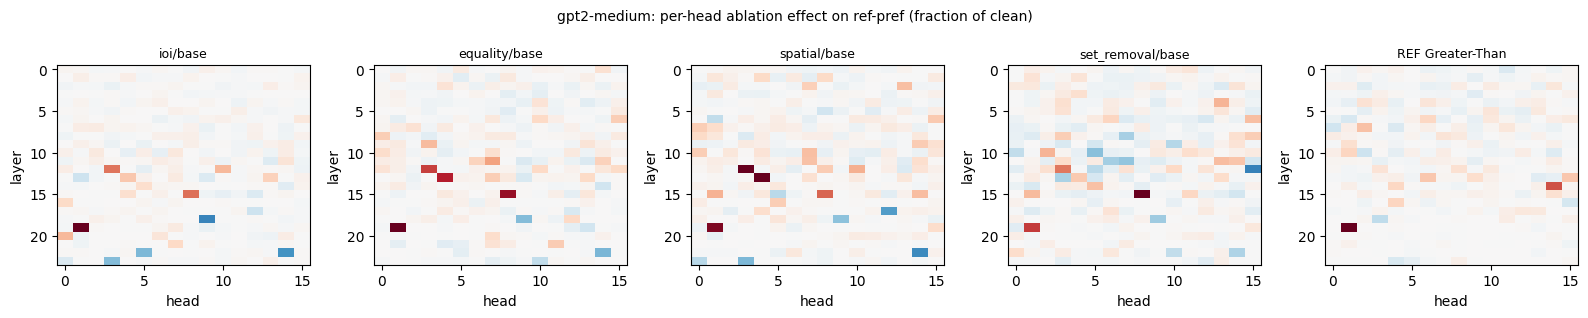


===== gpt2 =====
condition             spearman vs IOI  top-15 Jaccard   top heads (role)
ioi/base                         1.00            1.00   8.10(inhib) 7.9(inhib) 8.6(inhib) 5.5(dup/i) 7.3(inhib) 3.0(dup/i) 5.9 10.0(mover)
equality/base                    0.25            0.15   8.10(inhib) 4.11 10.7(neg m) 11.10(neg m) 7.9(inhib) 0.1(dup/i) 5.5(dup/i) 0.3
spatial/base                     0.51            0.30   8.10(inhib) 0.10(dup/i) 7.3(inhib) 7.9(inhib) 5.1 5.9 2.11 1.3
set_removal/base                 0.19            0.43   10.7(neg m) 8.10(inhib) 0.1(dup/i) 11.10(neg m) 7.9(inhib) 0.10(dup/i) 5.5(dup/i) 7.3(inhib)
REF Greater-Than                 0.08            0.15   9.1 10.7(neg m) 0.10(dup/i) 8.5 5.8 4.5 6.4 6.9(dup/i)


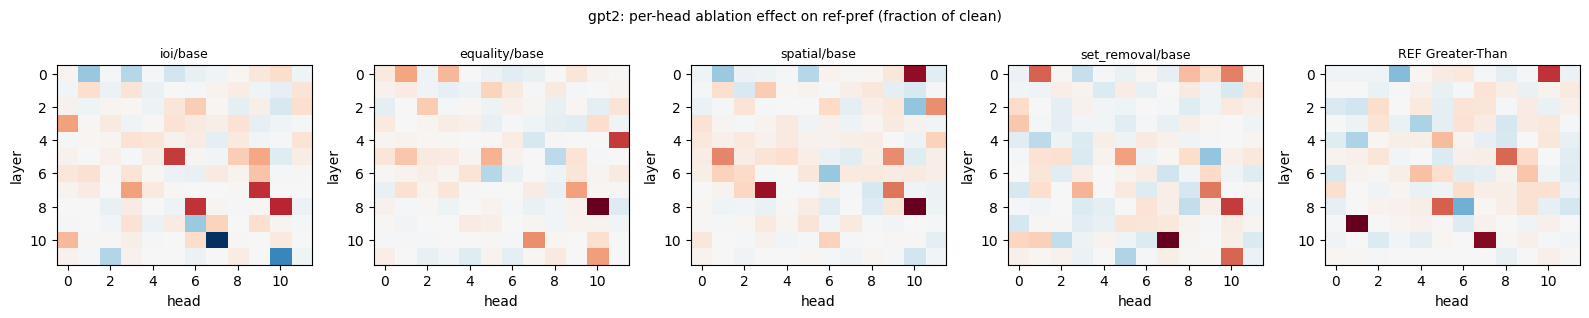

In [13]:
def rank(a):
    return np.argsort(np.argsort(a)).astype(float)


def spearman(a, b):
    return float(np.corrcoef(rank(a.ravel()), rank(b.ravel()))[0, 1])


def topk(E, k=15):
    return {(int(i // E.shape[1]), int(i % E.shape[1])) for i in np.argsort(-E.ravel())[:k]}


T6 = {}
for m in ALL:
    S, groups = ALL[m]["S"], ALL[m]["groups"]
    if "ioi/base" not in S:
        continue
    named = {h: g for g, hs in groups.items() for h in hs}
    print(f"\n===== {m} =====")
    print(f"{'condition':20s} {'spearman vs IOI':>16s} {'top-15 Jaccard':>15s}   top heads (role)")
    T6[m] = {}
    for name, E in S.items():
        sp, jac = spearman(E, S["ioi/base"]), len(topk(E) & topk(S["ioi/base"])) / len(topk(E) | topk(S["ioi/base"]))
        T6[m][name] = dict(spearman=sp, jaccard=jac)
        top = [f"{l}.{h}{'(' + named[(l, h)][:5] + ')' if (l, h) in named else ''}" for l, h in sorted(topk(E, 8), key=lambda x: -E[x])]
        print(f"{name:20s} {sp:16.2f} {jac:15.2f}   {' '.join(top)}")
    fig, ax = plt.subplots(1, len(S), figsize=(3.2 * len(S), 3.2))
    for a, (name, E) in zip(np.atleast_1d(ax), S.items()):
        v = np.nanmax(np.abs(E)) or 1
        a.imshow(E, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto"); a.set_title(name, fontsize=9)
        a.set_xlabel("head"); a.set_ylabel("layer")
    plt.suptitle(f"{m}: per-head ablation effect on ref-pref (fraction of clean)", fontsize=10)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/head_map_{m}.png", dpi=130); plt.show()

## Claims check (pilot)
| Claim | Supported if |
|---|---|
| C1 Repetition is the trigger | No-repeat twins lose ≥ 70% of base ref-pref in most exclusion tasks |
| C2 The relation is ignored | Invalid flips change ref-pref by < 25%; valid flips (elimination, set removal) accuracy < 0.5 |
| C3 Trigger = repeat of the query subject, not mention counts | TripleIO-analogue accuracy ≥ 0.90 |
| C4 Relation-blind with three entities | Two-step minus adjacent accuracy ≥ 0.30 at 0 shots |
| C5 Not a format failure | Relation-only stays below chance + 0.20 with 2 solved examples |
| C6 Same heads as IOI | Exclusion tasks' head maps correlate with IOI's ≥ 0.20 more than Greater-Than's does |

In [14]:
CLAIMS = {}
for m in ALL:
    R = ALL[m]["R"]
    c = {}
    t1 = T1.get(m, {})
    col = [v["collapse"] for v in t1.values() if not np.isnan(v["collapse"])]
    c["C1 repetition is the trigger"] = (f"{sum(x >= TH['norep_collapse'] for x in col)}/{len(col)} tasks collapse",
                                         len(col) > 0 and np.mean([x >= TH["norep_collapse"] for x in col]) > 0.5)
    inv = [t1[t]["flip_change"] for t in t1 if EXCL[t]["flip"] is None and not np.isnan(t1[t]["flip_change"])]
    val = [t1[t]["flip_acc"] for t in t1 if EXCL[t]["flip"] == "x"]
    c["C2 relation ignored"] = (f"invalid flips change {', '.join(f'{x:.0%}' for x in inv)}; valid flip acc {', '.join(f'{x:.2f}' for x in val)}",
                                len(inv) > 0 and all(x < TH["flip_insensitive"] for x in inv) and all(x < 0.5 for x in val))
    tr = {t: v["triple"] for t, v in T2.get(m, {}).items()}
    c["C3 trigger = query-subject repeat"] = (", ".join(f"{t} {x:.2f}" for t, x in tr.items()),
                                              len(tr) > 0 and np.mean([x >= TH["triple_hold"] for x in tr.values()]) > 0.5)
    gaps = {k: v["gap"] for k, v in T3.get(m, {}).items() if k.endswith("/0-shot")}
    c["C4 relation-blind, 3 entities"] = (", ".join(f"{k} gap {x:+.2f}" for k, x in gaps.items()),
                                          len(gaps) > 0 and all(x >= TH["chain_gap"] for x in gaps.values()))
    two = {k: v["acc"] for k, v in T4.get(m, {}).items() if k.endswith("/2-shot")}
    c["C5 not a format failure"] = (", ".join(f"{k} {x:.2f}" for k, x in two.items()),
                                    len(two) > 0 and all(x < 0.5 + TH["fewshot_margin"] for x in two.values()))
    if m in T6:
        gt = T6[m].get("REF Greater-Than", {}).get("spearman", np.nan)
        ex = {k: v["spearman"] for k, v in T6[m].items() if k not in ("ioi/base", "REF Greater-Than")}
        c["C6 same heads as IOI"] = (", ".join(f"{k} {x:.2f}" for k, x in ex.items()) + f" vs Greater-Than {gt:.2f}",
                                     len(ex) > 0 and all(x - gt >= TH["scan_gap"] for x in ex.values()))
    CLAIMS[m] = c
    print(f"\n===== {m} =====")
    for k, (txt, ok) in c.items():
        print(f"  {k:36s} {'SUPPORTED' if ok else 'not supported':14s} {txt}")


===== gpt2-medium =====
  C1 repetition is the trigger         SUPPORTED      6/6 tasks collapse
  C2 relation ignored                  not supported  invalid flips change 17%, 30%, 3%; valid flip acc 0.09, 0.29
  C3 trigger = query-subject repeat    not supported  equality 0.98, inequality 0.83, spatial 0.95, elimination 0.36, set_removal 0.27, ioi 0.96
  C4 relation-blind, 3 entities        not supported  chain-order/0-shot gap +0.18, chain-row/0-shot gap +0.15
  C5 not a format failure              SUPPORTED      relation-only-inequality/2-shot 0.45, relation-only-spatial/2-shot 0.51
  C6 same heads as IOI                 not supported  equality/base 0.37, spatial/base 0.29, set_removal/base 0.11 vs Greater-Than 0.08

===== gpt2 =====
  C1 repetition is the trigger         SUPPORTED      4/5 tasks collapse
  C2 relation ignored                  not supported  invalid flips change 9%, 28%, 1%; valid flip acc 0.14, 0.48
  C3 trigger = query-subject repeat    not supported  equality 0

## Figure and saved results

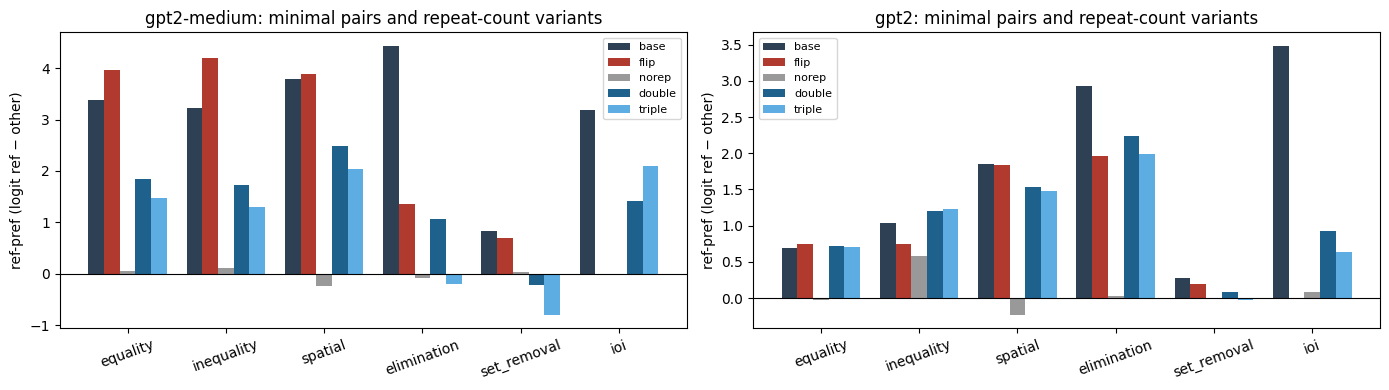

Saved: ['head_map_gpt2-medium.png', 'head_map_gpt2.png', 'minimal_pairs.png', 'results.json']


In [15]:
fig, axes = plt.subplots(1, len(ALL), figsize=(7 * len(ALL), 4), squeeze=False)
for a, m in zip(axes[0], ALL):
    R = ALL[m]["R"]; tasks = [t for t in EXCL if f"{t}/base" in R]
    w = 0.16
    for j, (v, col) in enumerate([("base", "#2e4053"), ("flip", "#b03a2e"), ("norep", "#999"), ("double", "#1f618d"), ("triple", "#5dade2")]):
        vals = [R[f"{t}/{v}"]["ref_pref"] if f"{t}/{v}" in R else np.nan for t in tasks]
        a.bar(np.arange(len(tasks)) + (j - 2) * w, vals, w, color=col, label=v)
    a.axhline(0, c="k", lw=.8); a.set_xticks(range(len(tasks))); a.set_xticklabels(tasks, rotation=20)
    a.set_ylabel("ref-pref (logit ref − other)"); a.set_title(f"{m}: minimal pairs and repeat-count variants"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/minimal_pairs.png", dpi=130); plt.show()


def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.floating, np.integer, np.bool_)): return o.item()
    if isinstance(o, torch.Tensor): return o.tolist()
    return o


config = {k: globals()[k] for k in ["MODELS", "TL_VERSION", "SMOKE", "QUICK", "SEED", "PREPEND_BOS", "N_PER", "N_RAND_SETS",
                                    "N_SCAN", "SHOTS", "MODEL_CFG", "SCAN_CONDS", "TH"]}
results = dict(config=config, claims=CLAIMS, T1=T1, T2=T2, T3=T3, T4=T4, T6=T6,
               models={m: dict(R=v["R"], head_maps=v["S"], minutes=v["minutes"]) for m, v in ALL.items()},
               prompts={k: [dict(text=q["text"], candidates=q["out_words"][:3], correct=q.get("correct"), ref=q.get("ref"))
                            for q in c["P"][:15]] for k, c in C_SHARED.items()})
with open(f"{OUT_DIR}/results.json", "w") as fh:
    json.dump(to_jsonable(results), fh, indent=1)
print("Saved:", sorted(os.listdir(OUT_DIR)))
if SAVE_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    shutil.copytree(OUT_DIR, f"/content/drive/MyDrive/{OUT_DIR}", dirs_exist_ok=True)

## Notes
1. **Resample partners** share token length and variant, which for these templates means the same
   template, so positions align. The `resample partners` column in the prompt table shows the share of
   prompts that got a different partner; the rest fall back to themselves (no-op).
2. **Invalid flips** have no correct answer; only the change in ref-pref is interpreted. A model that
   reads the relation should lose confidence there; a relation-blind one shouldn't.
3. **No-repeat twins** add a third entity that is not a candidate. A model could, in principle, answer
   with it; the analysis only compares the two original candidates.
4. **GPT-2 small head lists** are Wang et al.'s for IOI. Backup name movers (9.0, 9.7, 10.1, 10.2, 10.6,
   10.10, 11.2, 11.9) are deliberately not in the mover group, so mover ablation there is a lower bound.
5. **Thresholds** in `TH` are proposals. Fix them from this pilot, then rerun on fresh prompts (new `SEED`).